<a href="https://colab.research.google.com/github/ellecarpenter/QM2/blob/main/w03_spatial_data_uclqgc3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Spatial & Network Data

## *Workshop 3*  [![Open In Colab](https://github.com/oballinger/BASC0005/blob/main/colab-badge.png?raw=1)](https://colab.research.google.com/github/oballinger/BASC0005/blob/main/notebooks/W03.%20Spatial%20Data.ipynb)

In the lecture we followed Ukrainian grain through the Kerch Strait using **AIS** (the signal ships broadcast with their position) and satellite imagery. That used two kinds of data: **spatial data** (where things are) and **network data** (what is connected to what).

Today, on real data:

1. **Vector data**: is fishing off the Galápagos Islands inside or outside national waters?
2. **Raster data**: the same fishing data as an image. Where did fishing increase?
3. **Networks**: the London Underground, then the ships from the lecture.

**How to work:** most of the code is already written. Run each cell, read what it does, then try the exercises (they mostly mean copying a cell and changing one or two things). The **Extension** at the end is optional, for anyone who finishes early.

**Data:** Fishing effort © [Global Fishing Watch](https://globalfishingwatch.org), CC BY-NC 4.0 (`fishing_effort_v3`). EEZ boundaries: [Marine Regions](https://www.marineregions.org) (Flanders Marine Institute, EEZ v12, CC BY 4.0). Land: [Natural Earth](https://www.naturalearthdata.com). Cholera data: digitised by [Robin Wilson](https://blog.rtwilson.com/john-snows-cholera-data-in-more-formats/) from Snow's map. Tube network: [nicola/tubemaps](https://github.com/nicola/tubemaps). Kerch transfers: [oballinger.github.io/STS](https://oballinger.github.io/STS/).

In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx

URL = "https://storage.googleapis.com/qm2/2627/w03/"

# Part 1: Vector Data

In July 2020, around 300 Chinese fishing vessels, mostly **squid jiggers**, gathered off the Galápagos Islands, one of the most protected marine areas on Earth. They were fishing legally *if* they stayed outside Ecuador's **Exclusive Economic Zone** (EEZ: the waters up to 200 nautical miles from a country's coast, where that country controls fishing).

**Our question:** how much fishing happens inside each country's EEZ, and how much on the **high seas** outside them?

The data comes from [Global Fishing Watch](https://globalfishingwatch.org), which uses AIS to estimate how many hours vessels spent fishing in each small grid cell (about 11 km × 11 km). Each row is one **grid cell × year × flag × gear type**; `lat` and `lon` give the centre of the cell.

In [ ]:
# reads URL with the ending 'gfw_effort_galapagos.csv' to read that specific file
effort = pd.read_csv(URL + "gfw_effort_galapagos.csv")
effort.head()

,year,lat,lon,flag,geartype,fishing_hours
0,2020,-11.95,-101.95,JPN,drifting_longlines,4.84
1,2020,-11.95,-101.85,JPN,drifting_longlines,3.47
2,2020,-11.95,-101.75,JPN,drifting_longlines,4.56
3,2020,-11.95,-101.65,ESP,drifting_longlines,1.47
4,2020,-11.95,-101.65,JPN,drifting_longlines,6.50


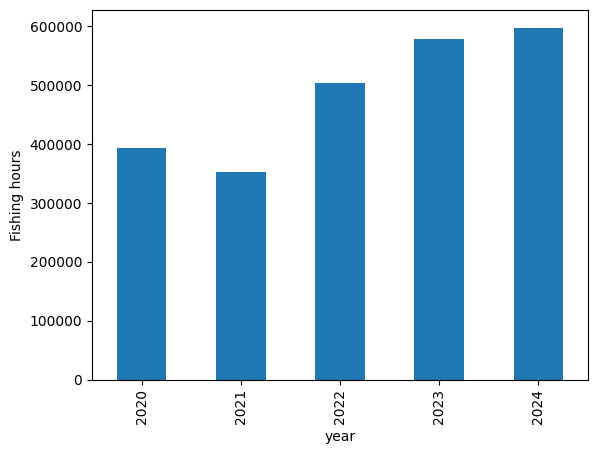

In [ ]:
# .groupby() = 'I want to organize all rows into groups based on the unique values in the year column, allowing up to perform calculations
# ['fishing_hours'] = after grouping data by year, we're looking at the fishing_hours column for calcs
# .sum() = sums the fishing_hours, organized by year, then we .plot()
effort.groupby("year")["fishing_hours"].sum().plot(kind="bar")
plt.ylabel("Fishing hours")
plt.show()

## Points: from a table to a GeoDataFrame

Right now `lat` and `lon` are just two columns of numbers. A **GeoDataFrame** is a normal DataFrame plus a `geometry` column that Python knows is a location, so we can draw maps and ask spatial questions. `crs="EPSG:4326"` says the numbers are ordinary longitude/latitude in degrees.

We'll use 2024 only.

In [ ]:
# effort["year"] == 2024 - conditional statement. Returns True if the 'year' is 2024
# e24 = values in effort during year 2024
e24 = effort[effort["year"] == 2024]

# gdp.GeoDataFrame(e24...) - function creating the base table from the set e24
# geometry=gpd.points_from_xy(e24["lon"], e24["lat"] - needs to know where things are (grabbing 'lon' and 'lat' values from data)
# crs="EPSG:4326" -  these longitude and latitude coordinates are standard, unprojected coordinates on a spherical Earth
cells = gpd.GeoDataFrame(e24, geometry=gpd.points_from_xy(e24["lon"], e24["lat"]), crs="EPSG:4326")
cells.head()

,year,lat,lon,flag,geartype,fishing_hours,geometry
135587,2024,-11.95,-101.85,ECU,fishing,0.91,POINT (-101.85 -11.95)
135588,2024,-11.95,-101.65,JPN,drifting_longlines,1.43,POINT (-101.65 -11.95)
135589,2024,-11.95,-101.55,JPN,drifting_longlines,0.92,POINT (-101.55 -11.95)
135590,2024,-11.95,-101.45,JPN,drifting_longlines,0.62,POINT (-101.45 -11.95)
135591,2024,-11.95,-100.75,ECU,fishing,0.33,POINT (-100.75 -11.95)


## Polygons

Now the areas: one **polygon** per EEZ, plus land for context. These come as **GeoJSON** files, which `gpd.read_file` opens straight into a GeoDataFrame.

In [ ]:
eez = gpd.read_file(URL + "eez_galapagos.geojson")
land = gpd.read_file(URL + "land_galapagos.geojson")
eez

,eez,sovereign,mrgid,geometry
0,Peru,Peru,8432,"POLYGON ((-80.30629 -3.3957, -80.29382 -3.4106..."
1,Panama,Panama,8423,"MULTIPOLYGON (((-78.42528 8, -78.42378 7.97825..."
2,Costa Rica,Costa Rica,8424,"POLYGON ((-82.91337 8, -84.31667 5, -84.31667 ..."
3,Colombia,Colombia,8426,"MULTIPOLYGON (((-76.92174 8, -76.73192 7.99777..."
4,Ecuador (Galapagos),Ecuador,8403,"POLYGON ((-87.1365 2.14762, -86.47134 1.14687,..."
5,Ecuador (mainland),Ecuador,8431,"POLYGON ((-83.45583 1.45667, -78.85013 1.45654..."


To put several layers on one map, draw the first one and save it as `ax`, then pass `ax=ax` to the others so they're drawn on the same map.

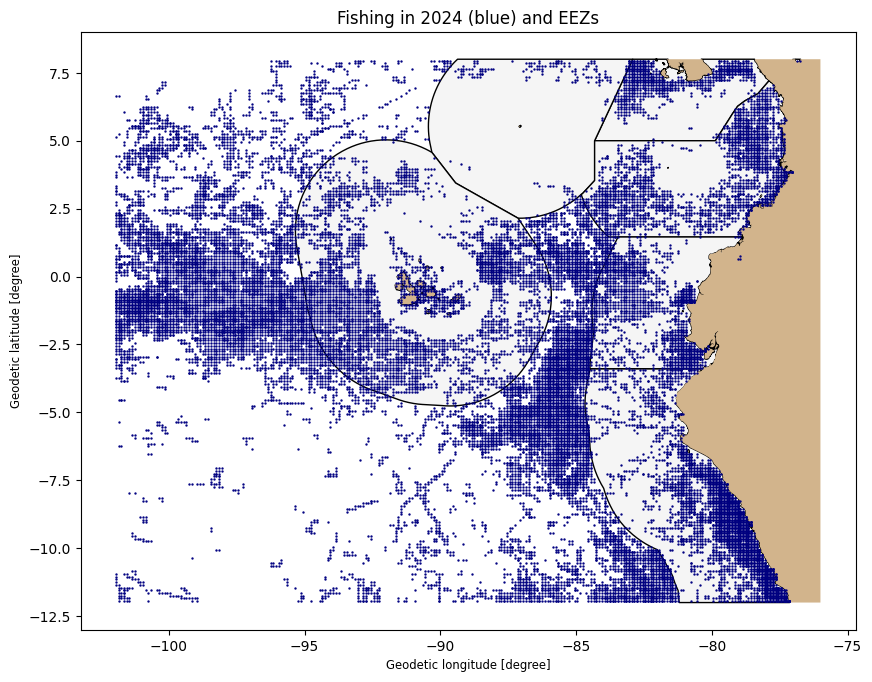

In [ ]:
ax = eez.plot(figsize=(10, 8), color="whitesmoke", edgecolor="black")   # EEZ polygons
land.plot(ax=ax, color="tan")                                            # land
cells.plot(ax=ax, markersize=0.5, color="navy")                          # fishing cells (points)
plt.title("Fishing in 2024 (blue) and EEZs")
plt.show()

The round EEZ in the middle is the Galápagos. Look at where the fishing is, compared with its edges.

### Exercise 1
Make the same map for **squid jiggers only**, coloured by fishing hours:

1. Filter: `squid = cells[cells["geartype"] == "squid_jigger"]`
2. Copy the map cell above and plot `squid` instead of `cells`.
3. Colour the points by hours: inside `squid.plot(...)`, replace `color="navy"` with `column="fishing_hours", vmax=500, legend=True`.

In one sentence: where is the squid fleet fishing, compared with the EEZ boundaries?

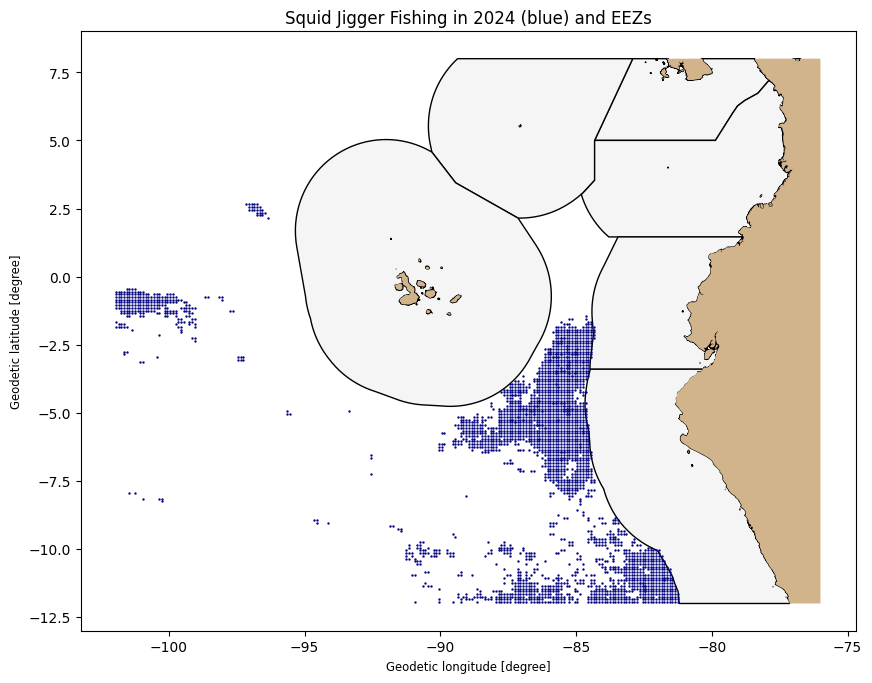

In [ ]:
# your code here
squid = cells[cells["geartype"] == "squid_jigger"]

ax = eez.plot(figsize=(10,8), color="whitesmoke", edgecolor="black")
land.plot(ax=ax, color="tan")                                            # land
squid.plot(ax=ax, markersize=0.5, color="navy")                          # fishing cells (points)
plt.title("Squid Jigger Fishing in 2024 (blue) and EEZs")
plt.show()

## Spatial join: which EEZ is each cell in?

A normal `merge` matches rows using a shared column. A **spatial join** matches rows using location: here, *which EEZ polygon is each point inside?* The result is our fishing table with an extra `eez` column.

`how="left"` keeps the points that are inside *no* EEZ. Those are on the high seas, so we fill in their missing `eez` with `"High seas"`.

In [ ]:
# gpd.sjoin() - matches rows based on their location (in data set cells)
# .sjoin(cells, eez, ...) the two sets we're joining
# how='left' ensures we keep every point from the cells dataset, even if it doesn't fall inside any EEZ
# predicate="within" defines spatial relationship. Tells python to find if a point from cells is located within an EEZ polygon
joined = gpd.sjoin(cells, eez, how="left", predicate="within")

# replaces null values in the new column eez with label 'high seas'
joined["eez"] = joined["eez"].fillna("High seas")
joined.head()

,year,lat,lon,flag,geartype,fishing_hours,geometry,index_right,eez,sovereign,mrgid
135587,2024,-11.95,-101.85,ECU,fishing,0.91,POINT (-101.85 -11.95),NaN,High seas,NaN,NaN
135588,2024,-11.95,-101.65,JPN,drifting_longlines,1.43,POINT (-101.65 -11.95),NaN,High seas,NaN,NaN
135589,2024,-11.95,-101.55,JPN,drifting_longlines,0.92,POINT (-101.55 -11.95),NaN,High seas,NaN,NaN
135590,2024,-11.95,-101.45,JPN,drifting_longlines,0.62,POINT (-101.45 -11.95),NaN,High seas,NaN,NaN
135591,2024,-11.95,-100.75,ECU,fishing,0.33,POINT (-100.75 -11.95),NaN,High seas,NaN,NaN


Now it's an ordinary `groupby`, like last week: total fishing hours in each EEZ, then as a percentage of all fishing.

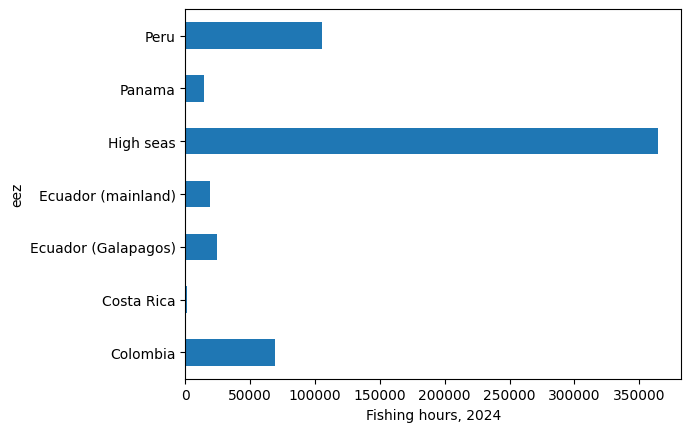

,fishing_hours
eez,
Colombia,11.575547
Costa Rica,0.175268
Ecuador (Galapagos),4.125754
Ecuador (mainland),3.124167
High seas,60.894754
Panama,2.443363
Peru,17.661148


In [ ]:
by_eez = joined.groupby("eez")["fishing_hours"].sum()
by_eez.plot(kind="barh")
plt.xlabel("Fishing hours, 2024")
plt.show()

100 * by_eez / by_eez.sum()

### Exercise 2
Repeat this for **Chinese-flagged vessels only**. What percentage of their fishing hours is on the high seas?

Hint: filter first, `chn = joined[joined["flag"] == "CHN"]`, then copy the cell above and change `joined` to `chn`.

,fishing_hours
eez,
Ecuador (Galapagos),647.93
Ecuador (mainland),351.76
High seas,277434.70
Peru,944.19


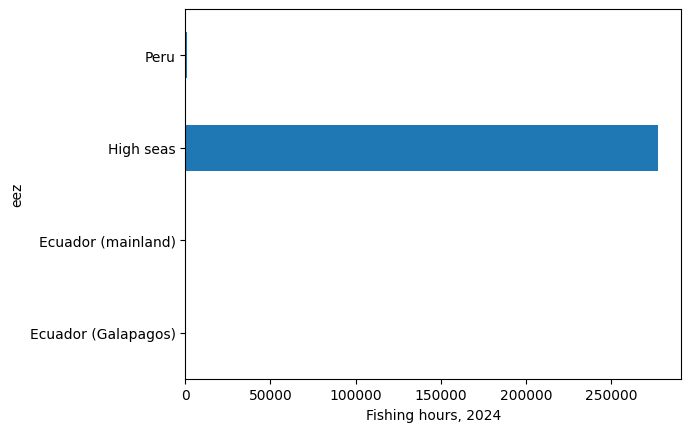

,fishing_hours
eez,
Colombia,11.575547
Costa Rica,0.175268
Ecuador (Galapagos),4.125754
Ecuador (mainland),3.124167
High seas,60.894754
Panama,2.443363
Peru,17.661148


In [ ]:
# your code here
# this is the data frame
chn = joined[joined["flag"]=="CHN"]

chn_fishing_hours = chn.groupby("eez")["fishing_hours"].sum()
display(chn_fishing_hours)

chn_fishing_hours.plot(kind="barh")
plt.xlabel("Fishing hours, 2024")
plt.show()

100 * by_eez / by_eez.sum()


# Part 2: Raster Data

A **raster** is a grid of cells, each holding a value, like the pixels of a satellite image. Our fishing data is already a grid, so we can turn it into an image.

The next cell defines two helper functions. **You don't need to understand how they work**, just run it:

- `to_raster(data)` adds up the fishing hours in each grid cell and returns a raster
- `show_raster(raster, title)` draws it, with the EEZ boundaries on top

In [ ]:
EXTENT = [-102, -76, -12, 8]   # left, right, bottom, top edges of our study area (degrees)

def to_raster(df, res=0.1):
    """Add up fishing hours onto a grid of res x res degree cells. Returns a 2-D array (an image)."""
    lon0, lon1, lat0, lat1 = EXTENT
    grid = np.zeros((round((lat1 - lat0) / res), round((lon1 - lon0) / res)))
    row = ((df["lat"] - lat0) // res).astype(int)
    col = ((df["lon"] - lon0) // res).astype(int)
    np.add.at(grid, (row, col), df["fishing_hours"])
    return grid

def show_raster(grid, title, change=False):
    """Draw a raster with EEZ boundaries. change=True uses a red/blue scale for differences."""
    fig, ax = plt.subplots(figsize=(10, 8))
    if change:
        im = ax.imshow(grid, origin="lower", extent=EXTENT, cmap="RdBu_r", vmin=-300, vmax=300)
        label = "Change in fishing hours"
    else:
        im = ax.imshow(np.log10(grid + 1), origin="lower", extent=EXTENT, cmap="magma")
        label = "log10(fishing hours + 1)"
    eez.boundary.plot(ax=ax, color="grey", linewidth=0.5)
    land.plot(ax=ax, color="lightgrey")
    plt.colorbar(im, label=label, shrink=0.7)
    ax.set_title(title)
    plt.show()

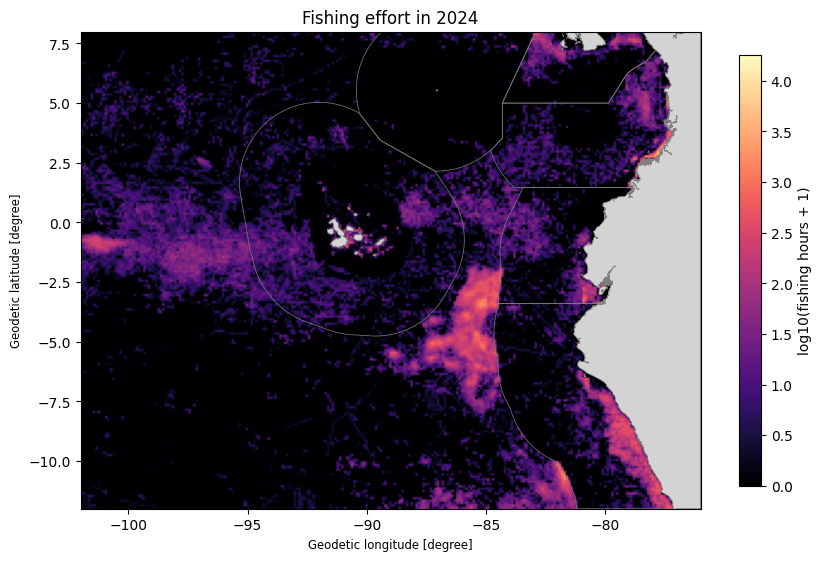

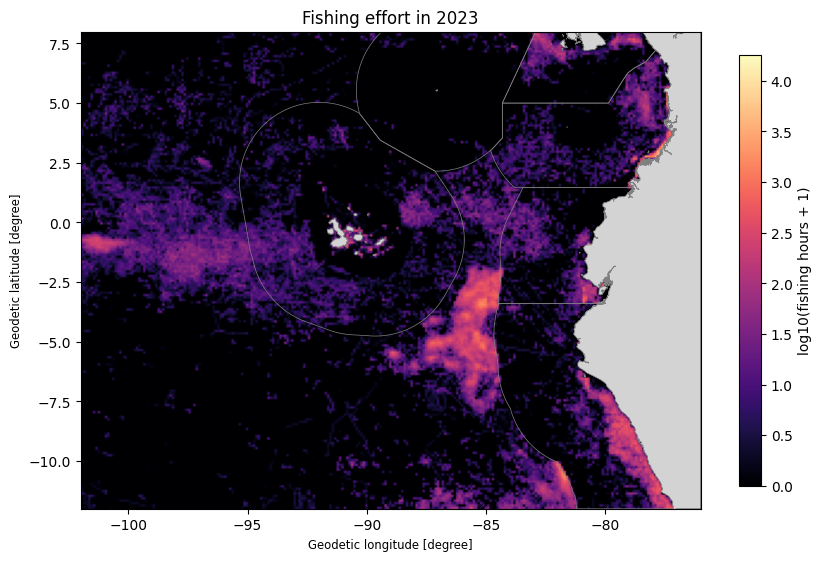

In [ ]:
r24 = to_raster(effort[effort["year"] == 2024])
show_raster(r24, "Fishing effort in 2024")

The colours use a **log scale**: a few cells have thousands of hours and most have very few, so on a normal scale you'd only see a handful of bright dots.

## Raster maths

Rasters covering the same grid can be added or subtracted cell by cell, like the lecture's night-time lights example. Where did fishing **increase** or **decrease** between 2020 and 2024?

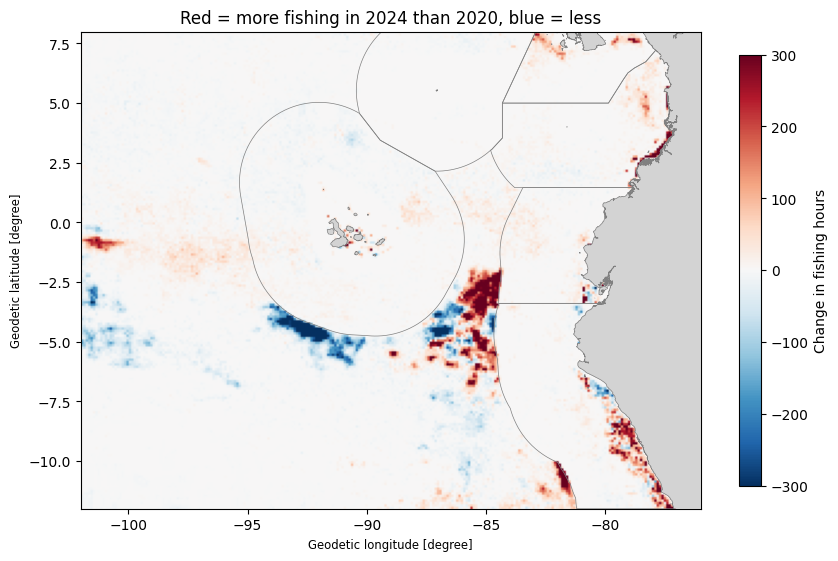

In [ ]:
# filters raster data in 2020
r20 = to_raster(effort[effort["year"] == 2020])
change = r24 - r20      # one line of raster maths: every cell at once

# change=True uses diverging
show_raster(change, "Red = more fishing in 2024 than 2020, blue = less", change=True)

### Exercise 3
Make the same change map for **squid jiggers only**. Has the squid fleet moved?

Hint: start with `squid = effort[effort["geartype"] == "squid_jigger"]`, then copy the cells above, swapping `effort` for `squid`. Bonus: `change.sum()` adds up every cell. Did the squid fleet fish more or less overall?

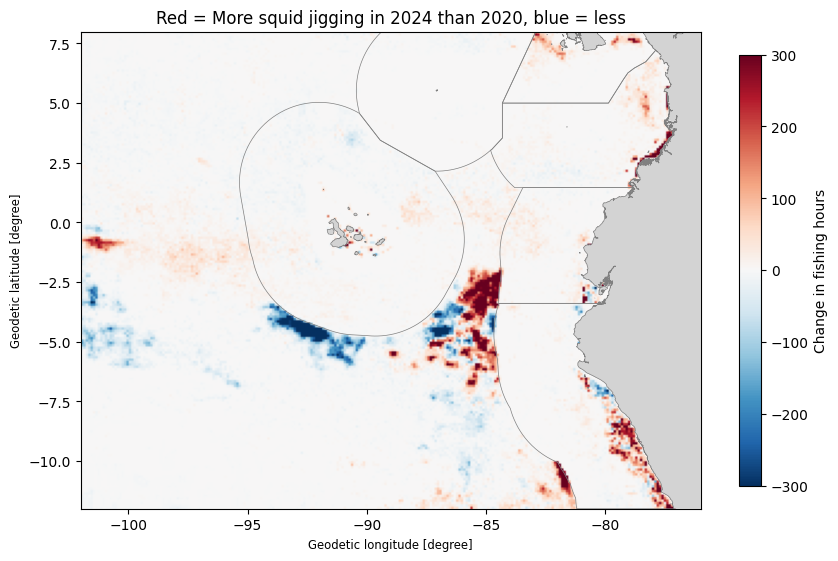

np.float64(-15849.16)

In [ ]:
# your code here
squid = effort[effort['geartype']=='squid_jigger']

# aggregate squid jigger hours in 2024
squid_effort_24 = to_raster(squid[squid["year"] == 2024])

# aggregate squid jigger hours in 2020
squid_effort_20 = to_raster(squid[squid["year"] == 2020])

# calculate the change in squid jigger effort
squid_effort_change = squid_effort_24 - squid_effort_20

# calls show_raster() function, change=True uses diverging
show_raster(change, "Red = More squid jigging in 2024 than 2020, blue = less", change=True)

change_in_squid_jigging = squid_effort_change.sum()
change_in_squid_jigging

# result was: np.float64(-15849.16000000001) - negative value implies that less fishing was done in 2024 compared to 2020
# by 15,849 hours

# Part 3: Networks

A network is a set of **nodes** (things) connected by **edges** (relationships). A node's **degree** is how many edges it has. Networks are usually stored as an **edge list**: a table with one row per edge, which we load with pandas.

## The London Underground

Stations are nodes; an edge joins two neighbouring stations, with the travel `time` in minutes. (The data is from about 2007: no Overground or Elizabeth line.)

In [ ]:
TUBE = "https://raw.githubusercontent.com/nicola/tubemaps/master/datasets/"
stations = pd.read_csv(TUBE + "london.stations.csv")
connections = pd.read_csv(TUBE + "london.connections.csv")
connections.head()

,station1,station2,line,time
0,11,163,1,1
1,11,212,1,2
2,49,87,1,1
3,49,197,1,2
4,82,163,1,2


The edge list uses station ID numbers. The next cell swaps in station names, then `nx.from_pandas_edgelist` turns the table into a network.

,source
0,Baker Street
1,Baker Street
2,Charing Cross
3,Charing Cross
4,Edgware Road (B)
...,...
401,Pimlico
402,Pimlico
403,Seven Sisters
404,Stockwell


,target
0,Marylebone
1,Regent's Park
2,Embankment
3,Picadilly Circus
4,Marylebone
...,...
401,Vauxhall
402,Victoria
403,Tottenham Hale
404,Vauxhall


302 stations, 349 links


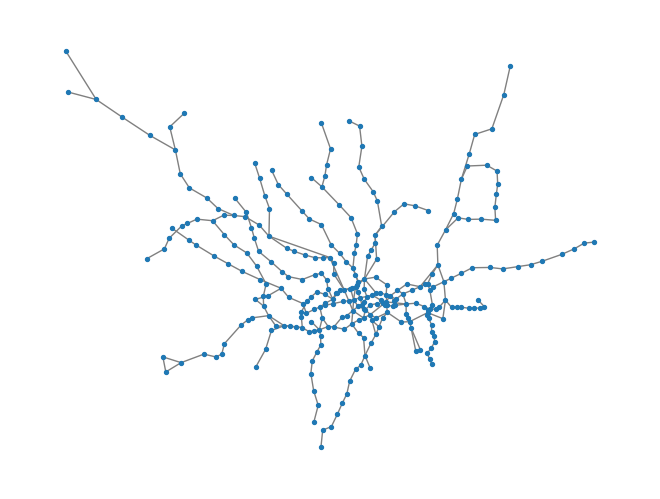

In [ ]:
# makes 'id' the column
id_to_name = stations.set_index("id")["name"]

# creating new 'source' and 'target' columns
# .map() method to look up the ID numbers in 'station1' and 'station2' columns in connections. Replaces them with their corresponding station names.
connections["source"] = connections["station1"].map(id_to_name)
connections["target"] = connections["station2"].map(id_to_name)

display(connections["source"])
display(connections["target"])

#builds network graph tube from 'connections' DataFrame
#imports connections between stations from connections DF, using source column as start and target column as end
# edge attribute = 'time' - connections between nodes, varied by time between stations
tube = nx.from_pandas_edgelist(connections, "source", "target", edge_attr="time")
print(tube.number_of_nodes(), "stations,", tube.number_of_edges(), "links")

# maps each station to its real-world geographical coordinates
pos = {row["name"]: (row["longitude"], row["latitude"]) for _, row in stations.iterrows()}   # where to draw each station
# draws the graph
nx.draw(tube, pos=pos, node_size=8, edge_color="grey")
plt.show()

The quickest route between two stations is a **shortest path**. `weight="time"` means "add up the minutes"; without it you'd get the route with the fewest *stops*.

In [ ]:
route = nx.shortest_path(tube, "Brixton", "Camden Town", weight="time")
print(route)
print(nx.shortest_path_length(tube, "Brixton", "Camden Town", weight="time"), "minutes")

['Brixton', 'Stockwell', 'Vauxhall', 'Pimlico', 'Victoria', 'Green Park', 'Oxford Circus', 'Warren Street', 'Euston', 'Camden Town']
19 minutes


## The Kerch Strait transfer network

Now the lecture's case study. When two ships stayed within 500 m of each other for 2+ hours, AIS data shows a likely **ship-to-ship transfer**. Each row of `transfers` is one transfer between two vessels, so it's already an edge list. `vessels` has one row per ship.

In [ ]:
vessels = pd.read_csv(URL + "kerch_vessels.csv")
transfers = pd.read_csv(URL + "kerch_transfers.csv")
transfers.head()

,vessel_1,vessel_2,date
0,0,1,2022-02-24
1,8,11,2022-02-24
2,7,8,2022-02-24
3,8,9,2022-02-24
4,2,6,2022-02-24


In [ ]:
vessels.head()

,vessel_id,name,imo,vessel_type,type_detail,flag,dwt,length_m,sanctioned,named_in_grain_reports
0,0,Oxana-V,9077317,bulk carrier,bulk carrier,Panama,44822.0,176.0,0,0
1,1,Volgo-Don 5043,8866321,general cargo,general cargo,Russia,3650.0,138.0,0,1
2,2,Kavkaz V,9104574,bulk carrier,bulk carrier,Panama,45664.0,178.0,0,0
3,3,Yekaterina,9874791,general cargo,general cargo,Russia,7867.0,139.0,0,0
4,4,Amazon,9233260,bulk carrier,bulk carrier,Greece,74910.0,217.0,0,0


In [ ]:
# grabs from df 'transfers' and columns vessel 1 and vessel 2
kerch = nx.from_pandas_edgelist(transfers, "vessel_1", "vessel_2")
print(kerch.number_of_nodes(), "vessels,", kerch.number_of_edges(), "pairs of vessels that transferred")

722 vessels, 4009 pairs of vessels that transferred


## Who matters? Centrality

Centrality = the degree of connectedness of the nodes in a graph

Two ways to be central, from the lecture:

- **Degree**: how many different vessels you transferred with (the popular one)
- **Betweenness**: how often you sit on the shortest path between other vessels (the broker)

We add both as columns to the `vessels` table (one row per vessel) and call it `cent`.

In [ ]:
cent = vessels.set_index("vessel_id")

# defines new column as the degree of vessels you transferred with (from dataset kerch) - represents the total number of unique, different ships that a particular vessel has made a transfer with
cent["degree"] = pd.Series(dict(kerch.degree()))

# how often a vessel acts as a bridge/broker between other ships (high betweenness if it sits directly on the shortest paths connecting many different pairs of ships)
cent["betweenness"] = pd.Series(nx.betweenness_centrality(kerch))

cent.sort_values("degree", ascending=False).head(10)

,name,imo,vessel_type,type_detail,flag,dwt,length_m,sanctioned,named_in_grain_reports,degree,betweenness
vessel_id,,,,,,,,,,,
62,Venera,9100097,bulk carrier,bulk carrier,Panama,43325.0,182.0,0,0,115,0.049079
182,Barla,8902462,bulk carrier,bulk carrier,Panama,41691.0,177.0,0,0,112,0.055212
81,Vladimir Monomakh,9842176,tanker,crude oil tanker,Russia,114000.0,250.0,0,0,95,0.139141
16,Horasan,8902474,bulk carrier,bulk carrier,Panama,41691.0,177.0,0,0,95,0.060620
104,Kavkaz II,9135664,bulk carrier,bulk carrier,Malta,42740.0,178.0,0,0,92,0.067158
199,Kavkaz I,9135652,bulk carrier,bulk carrier,Malta,42727.0,178.0,0,0,82,0.048478
2,Kavkaz V,9104574,bulk carrier,bulk carrier,Panama,45664.0,178.0,0,0,80,0.047676
74,Bafra,8902436,bulk carrier,bulk carrier,Panama,42264.0,177.0,0,0,68,0.019751
7,Roda,9077305,bulk carrier,bulk carrier,Panama,44809.0,176.0,0,0,67,0.029476


### Exercise 4
The column `named_in_grain_reports` is 1 for the 15 vessels named in media reports about grain taken from occupied Ukraine, and 0 otherwise. Are they more central than other vessels?

1. Compare the median degree of the two groups: `cent.groupby("named_in_grain_reports")["degree"].median()`
2. Sort `cent` by degree (like the cell above) and take the top 20 with `.head(20)`. How many of them are named in grain reports? (Hint: add up the `named_in_grain_reports` column with `.sum()`.)

In [ ]:
# your code here

vessels_named_in_grain_reports = cent.groupby("named_in_grain_reports")["degree"].median()
display(vessels_named_in_grain_reports)

display(cent.sort_values("degree", ascending=False).head(20))

cent.sort_values("degree", ascending=False).head(20)["named_in_grain_reports"].sum()

#There are 3 named in grain reports

,degree
named_in_grain_reports,
0,6.0
1,26.0


,name,imo,vessel_type,type_detail,flag,dwt,length_m,sanctioned,named_in_grain_reports,degree,betweenness,eigenvector,community
vessel_id,,,,,,,,,,,,,
62,Venera,9100097,bulk carrier,bulk carrier,Panama,43325.0,182.0,0,0,115,0.049079,0.228342,6
182,Barla,8902462,bulk carrier,bulk carrier,Panama,41691.0,177.0,0,0,112,0.055212,0.222659,6
81,Vladimir Monomakh,9842176,tanker,crude oil tanker,Russia,114000.0,250.0,0,0,95,0.139141,0.005202,0
16,Horasan,8902474,bulk carrier,bulk carrier,Panama,41691.0,177.0,0,0,95,0.060620,0.207790,6
104,Kavkaz II,9135664,bulk carrier,bulk carrier,Malta,42740.0,178.0,0,0,92,0.067158,0.097071,5
199,Kavkaz I,9135652,bulk carrier,bulk carrier,Malta,42727.0,178.0,0,0,82,0.048478,0.077457,5
2,Kavkaz V,9104574,bulk carrier,bulk carrier,Panama,45664.0,178.0,0,0,80,0.047676,0.091982,5
74,Bafra,8902436,bulk carrier,bulk carrier,Panama,42264.0,177.0,0,0,68,0.019751,0.157588,6
7,Roda,9077305,bulk carrier,bulk carrier,Panama,44809.0,176.0,0,0,67,0.029476,0.148340,6


np.int64(3)

## Spot the problem: what the network can't see

A journalist reads your results and writes:

> "Sanctioned vessels have *below-median* centrality in the Kerch transfer network. So sanctioned ships aren't central to the grain trade: sanctions have pushed them to the margins."

First check the numbers:

In [ ]:
cent.groupby("sanctioned")[["degree", "betweenness"]].median()

,degree,betweenness
sanctioned,,
0,6.5,0.000215
1,2.0,0.000032


### Exercise 5
The numbers are right, but is the conclusion? Write 3–4 bullet points. Think about:

- How were the edges detected? What if one ship has its AIS **switched off** (the lecture's "broker in the dark")?
- Would a sanctioned vessel *want* to be visible?
- Is "fewer *visible* transfers" the same as "fewer transfers"?
- What other data could test the journalist's claim?

*Your answer here (double-click to edit).*

- From the data: Sanctioned (restricted) vessels (1) have a lower degree and betweenness in the transfer network. This means they come into contact less with other vessels and they're less often going between ships.
- However, the edges are detected via GPS/AIS signals. A sanctioned vessel wouldn't want to be visible, and could turn off the GPS to not be identified within EEZs
- Spatial data of identified fishing ships within EEZs could test the journalist's claim

## Wrap-up

- **Vector** data is a table plus a geometry column: points, lines and polygons. **Raster** data is a grid of values, and rasters on the same grid can be subtracted cell by cell.
- A **spatial join** adds polygon information (here, the EEZ) to points; then you can `groupby` as usual.
- **Networks** are stored as edge lists. **Degree** and **betweenness** pick out different kinds of important node.
- A map or network only contains what the sensor can see. Centrality can tell you where to look; it can't prove anything.

Finished early? Try the Extension below.

# Assessed Question

The URL below contains Global Fishing Watch fishing effort for the same study area, in the same layout as `gfw_effort_galapagos.csv` above:

https://oballinger.github.io/BASC0005/data/assessed/w03_gfw_effort_galapagos.csv

Note that the file may have been corrupted; some values or labels may be wrong, so make sure to sense-check your data before answering.

**QUESTION: Consider only 2023 and only vessels flagged PER. What percentage of their fishing hours took place inside Peru's EEZ? (1 d.p.)**

Keep a note of your answer: you will enter it in the Problem Set Answers quiz on Moodle in December.

,year,lat,lon,flag,geartype,fishing_hours
105117,2023,-81.35,-11.95,PER,purse_seines,0.46
105118,2023,-81.25,-11.95,PER,purse_seines,2.26
105119,2023,-81.15,-11.95,PER,purse_seines,0.69
105120,2023,-81.05,-11.95,PER,purse_seines,0.51
105122,2023,-80.85,-11.95,PER,tuna_purse_seines,5.88
...,...,...,...,...,...,...
128703,2023,-85.75,1.55,PER,tuna_purse_seines,5.29
128822,2023,-85.95,1.65,PER,tuna_purse_seines,4.80
128824,2023,-85.85,1.65,PER,tuna_purse_seines,1.21
128826,2023,-85.75,1.65,PER,tuna_purse_seines,0.49


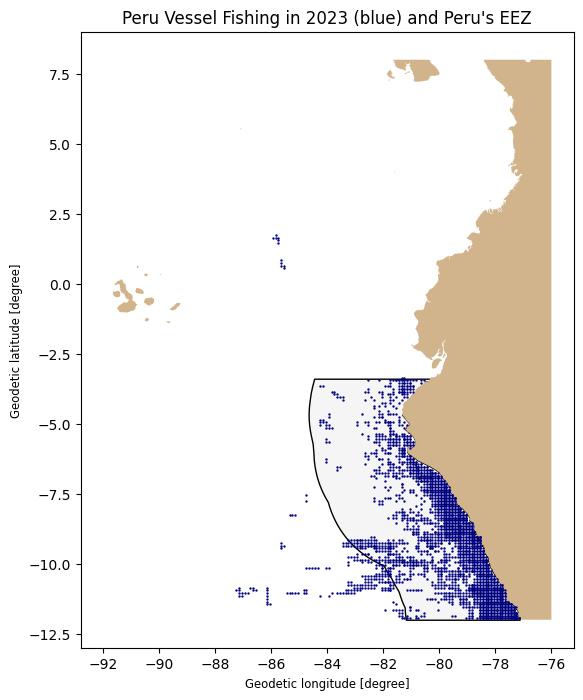

In 2023, vessels from Peru fished 73.7% of their fishing hours inside Peru's EEZ (Exlcusive Economic Zone)


In [91]:
# your code here
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx

URL = "https://storage.googleapis.com/qm2/2627/w03/"

#reading the csv
gfw_effort_df = pd.read_csv("https://oballinger.github.io/BASC0005/data/assessed/w03_gfw_effort_galapagos.csv")

#filtering dataframe for PER flagged vessels in 2023
effort_2023_PER = gfw_effort_df[(gfw_effort_df["year"] == 2023) & (gfw_effort_df["flag"]=="PER")]
display(effort_2023_PER)

# defining the points on the map (longitutde and latitude values appeared to be swapped in the dataset at first, distorting the dataset)
peru_2023_cells = gpd.GeoDataFrame(effort_2023_PER, geometry=gpd.points_from_xy(effort_2023_PER["lat"], effort_2023_PER["lon"]), crs="EPSG:4326")

# display PERU EEZs and 2023 Peru vessels fishing points
eez = gpd.read_file(URL + "eez_galapagos.geojson")
peru_eez = eez[eez["sovereign"] == "Peru"]    # getting only the peru EEZ zone, found in column 'sovereign'
land = gpd.read_file(URL + "land_galapagos.geojson")

ax = peru_eez.plot(figsize=(10, 8), color="whitesmoke", edgecolor="black")   # Peru EEZ polygon outline
land.plot(ax=ax, color="tan") # land outline
peru_2023_cells.plot(ax=ax, markersize=0.5, color="navy") # fishing cells (points)
ax.set_aspect('equal') # prevent horizontal squishing

plt.title("Peru Vessel Fishing in 2023 (blue) and Peru's EEZ")
plt.show()

# determining the percentage of fishing within Peru's EEZs

# matches rows based on physical geographic locations
# how="inner" filters, keeping rows where coordinate points are located inside Pery EEZ boundary
# predicate="within" - tells python to find if a point from cells is located within an EEZ polygon
inside_eez = gpd.sjoin(peru_2023_cells, peru_eez, how="inner", predicate="within")

total_peru_2023_fishing_hours = effort_2023_PER['fishing_hours'].sum() # total of all fishing hours in Peru
peru_2023_fishing_hours_inside = inside_eez['fishing_hours'].sum() # fishing hours inside the EEZ

percentage_hours_inside = 100 * (peru_2023_fishing_hours_inside / total_peru_2023_fishing_hours) # calculating the percentage

print(f"In 2023, vessels from Peru fished {percentage_hours_inside:.1f}% of their fishing hours inside Peru's EEZ (Exlcusive Economic Zone)") # printed, rounding to 1 decimal place



# Extension

Everything below is optional. It builds on the objects you made above (`effort`, `cells`, `eez`, `land`, `joined`, `r24`, `to_raster`, `tube`, `pos`, `kerch`, `cent`), so run the main notebook first.

## Coordinate reference systems

Degrees are fine for *storing* locations, but they are not a unit of distance or area: one degree of longitude is 111 km at the equator but only 69 km in London, and 0 km at the poles. So before we measure anything, we **project** the data into a CRS whose units are metres.

Watch what happens if we ask for the area of each EEZ while still in degrees:

In [ ]:
eez.area   # geopandas warns you: the answer is in "square degrees", which is meaningless

/tmp/ipykernel_8239/2218338212.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  eez.area   # geopandas warns you: the answer is in "square degrees", which is meaningless


,0
0,34.994628
1,13.654362
2,32.465182
3,26.670074
4,68.404455
5,19.203443


There's no single "correct" projection: every flat map distorts something. For areas and distances in this region I'll use a **Lambert Azimuthal Equal-Area** projection centred on the Galápagos (units: metres). `.to_crs()` converts every coordinate.

In [ ]:
PROJ = "+proj=laea +lat_0=-2 +lon_0=-89 +datum=WGS84 +units=m"   # equal-area, centred on our study area

eez_m = eez.to_crs(PROJ)
eez_m["area_km2"] = eez_m.area / 1e6
eez_m[["eez", "area_km2"]].round(0)

,eez,area_km2
0,Peru,426546.0
1,Panama,167085.0
2,Costa Rica,397682.0
3,Colombia,327605.0
4,Ecuador (Galapagos),841247.0
5,Ecuador (mainland),236292.0


(These are the parts of each EEZ inside our study box, not the whole EEZ.)

## Choropleths and area

Most of the fishing in this box is on the **high seas**. To map the EEZ totals from the spatial join, merge them back onto the polygons (an ordinary attribute join) and make a **choropleth**.

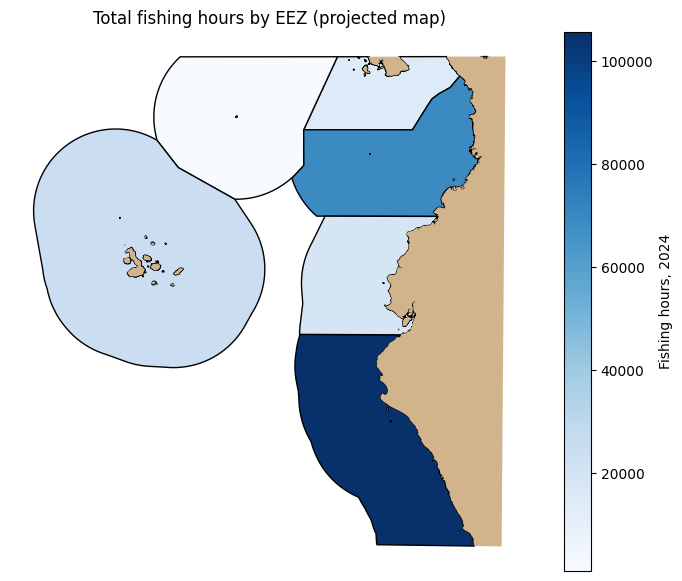

In [ ]:
eez_m = eez_m.merge(by_eez.rename("hours").reset_index(), on="eez", how="left")

fig, ax = plt.subplots(figsize=(9, 7))
eez_m.plot(ax=ax, column="hours", cmap="Blues", edgecolor="black", legend=True,
           legend_kwds={"label": "Fishing hours, 2024"})
land.to_crs(PROJ).plot(ax=ax, color="tan")
ax.set_title("Total fishing hours by EEZ (projected map)")
ax.set_axis_off()
plt.show()

### Area matters

Peru's slice of the box is much bigger than Panama's. Is Peru's EEZ fished more *intensively*, or just bigger? A choropleth of **totals** mostly shows you which polygons are large. Normalise by area:

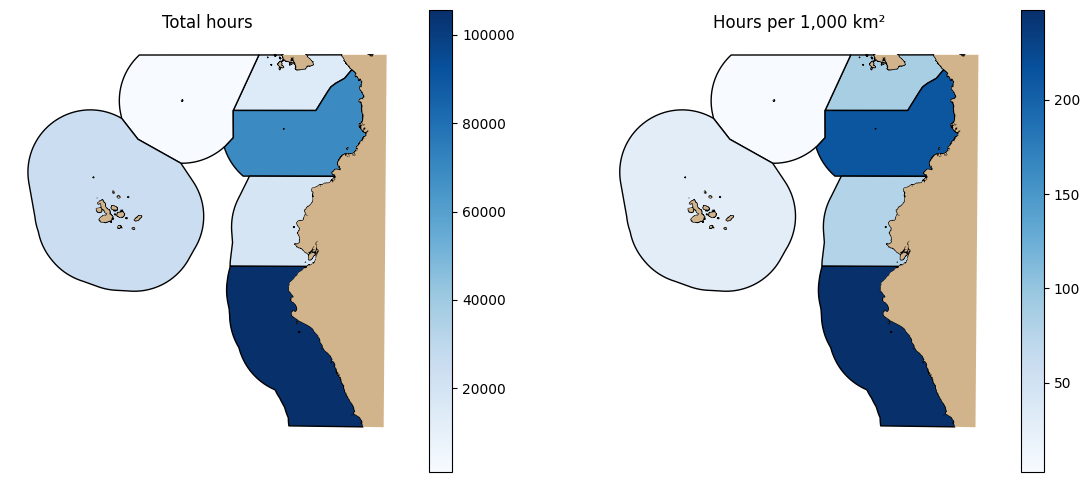

,eez,hours,area_km2,hours_per_1000km2
0,Peru,105624.6,426546.3,247.6
3,Colombia,69229.0,327605.2,211.3
1,Panama,14612.8,167085.5,87.5
5,Ecuador (mainland),18684.5,236292.4,79.1
4,Ecuador (Galapagos),24674.6,841246.6,29.3
2,Costa Rica,1048.2,397682.0,2.6


In [ ]:
eez_m["hours_per_1000km2"] = 1000 * eez_m["hours"] / eez_m["area_km2"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, col, title in zip(axes, ["hours", "hours_per_1000km2"], ["Total hours", "Hours per 1,000 km²"]):
    eez_m.plot(ax=ax, column=col, cmap="Blues", edgecolor="black", legend=True)
    land.to_crs(PROJ).plot(ax=ax, color="tan")
    ax.set_title(title)
    ax.set_axis_off()
plt.show()

eez_m[["eez", "hours", "area_km2", "hours_per_1000km2"]].sort_values("hours_per_1000km2", ascending=False).round(1)

**Question:** Which ranking would you report, and why? The Galápagos EEZ is huge but lightly fished: is that because it's protected, or could it be something about *who* the data can see? (Hint: AIS is mandatory for large vessels but many small coastal boats don't carry it.)

A related trap is the **Modifiable Areal Unit Problem (MAUP)**: your conclusions can change just by drawing the zones differently (EEZs vs. 1° grid squares vs. our study box). We'll see it again with rasters.

## Distance and buffers

Snow's insight and the lecture's ship-to-ship rule ("within 500 m for 2 hours") are both about **distance**. Let's ask: how far from the Galápagos EEZ boundary does the squid fleet fish? We'll use 2020, the year of the incident.

Distances must be computed in a projected CRS (metres). We make the distance **negative** for cells inside the EEZ, so 0 is exactly on the boundary line.

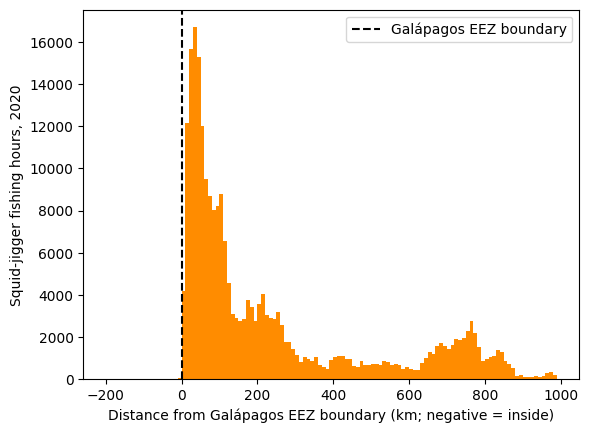

In [ ]:
galapagos = eez_m.loc[eez_m["eez"] == "Ecuador (Galapagos)", "geometry"].iloc[0]

squid20 = effort[(effort["year"] == 2020) & (effort["geartype"] == "squid_jigger")]
squid20 = gpd.GeoDataFrame(squid20, geometry=gpd.points_from_xy(squid20["lon"], squid20["lat"]),
                           crs="EPSG:4326").to_crs(PROJ)

dist_km = squid20.distance(galapagos.boundary) / 1000
squid20["dist_km"] = np.where(squid20.within(galapagos), -dist_km, dist_km)

plt.hist(squid20["dist_km"], bins=np.arange(-200, 1000, 10), weights=squid20["fishing_hours"], color="darkorange")
plt.axvline(0, color="black", linestyle="--", label="Galápagos EEZ boundary")
plt.xlabel("Distance from Galápagos EEZ boundary (km; negative = inside)")
plt.ylabel("Squid-jigger fishing hours, 2020")
plt.legend()
plt.show()

**Question:** Describe the shape of this distribution. What does the sharp edge at 0 tell you about how the fleet responds to the boundary? Does this plot show the fleet was fishing *illegally*?

### Buffers: an approximate marine reserve

The **Galápagos Marine Reserve** extends 40 nautical miles from the islands' baselines. A **buffer** draws a zone of fixed distance around a geometry. We can approximate the reserve by buffering the island polygons by 40 nm (1 nm = 1,852 m), in metres, of course.

Approximate reserve area: 134,619 km²  (published figures: roughly 133,000-138,000 km²)


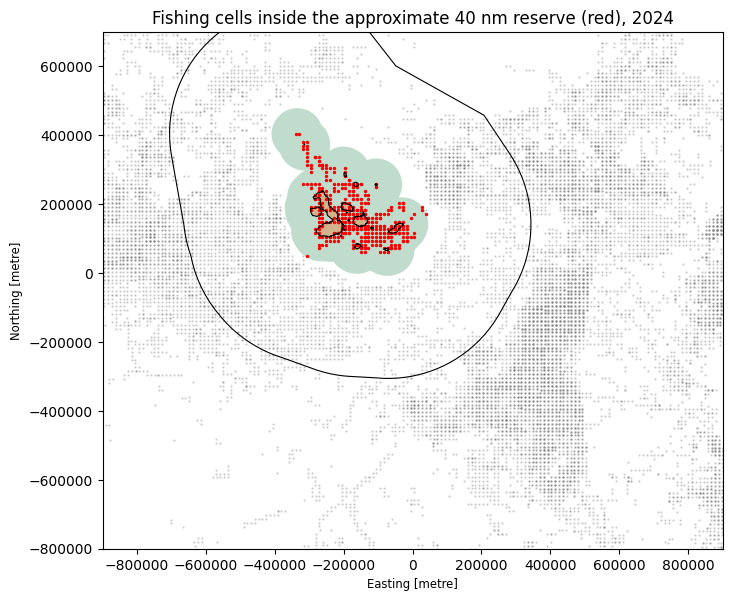

flag  geartype         
ECU   fishing              7178.20
      set_longlines        1321.74
      pole_and_line         192.61
      tuna_purse_seines     166.50
      trawlers               61.03
Name: fishing_hours, dtype: float64

In [ ]:
islands = land[land["name"] == "Galapagos"].to_crs(PROJ)
reserve = islands.union_all().buffer(40 * 1852)       # one shape: all islands merged, then buffered
print(f"Approximate reserve area: {reserve.area / 1e6:,.0f} km²  (published figures: roughly 133,000-138,000 km²)")

cells_m = cells.to_crs(PROJ)
in_reserve = cells_m[cells_m.within(reserve)]

fig, ax = plt.subplots(figsize=(8, 7))
gpd.GeoSeries([galapagos], crs=PROJ).boundary.plot(ax=ax, color="black", linewidth=0.8)
gpd.GeoSeries([reserve], crs=PROJ).plot(ax=ax, color="seagreen", alpha=0.3)
islands.plot(ax=ax, color="tan")
cells_m.plot(ax=ax, markersize=0.5, color="grey", alpha=0.3)
in_reserve.plot(ax=ax, markersize=2, color="red")
ax.set_xlim(-900e3, 900e3); ax.set_ylim(-800e3, 700e3)
ax.set_title("Fishing cells inside the approximate 40 nm reserve (red), 2024")
plt.show()

in_reserve.groupby(["flag", "geartype"])["fishing_hours"].sum().sort_values(ascending=False).head()

**Question:** Almost all fishing inside the reserve is by Ecuadorian vessels. Does that mean the reserve is being violated? What would you need to know? (Local artisanal fleets have permitted zones; our reserve is also an approximation: the real one is drawn from straight baselines around the whole archipelago, not circles around each island; and our cells are 11 km squares represented by their centre point.)

### Extension exercise A
Repeat the buffer analysis with a **wrong** buffer: `land[land["name"] == "Galapagos"].union_all().buffer(40 * 1852)`, i.e. buffer while still in EPSG:4326. Print its `.bounds`. What has gone wrong, and why didn't Python stop you?

In [ ]:
# your code here

## The Broad Street Pump (nearest feature)

In 1854, cholera killed hundreds of people in Soho. Most doctors blamed "bad air". John Snow mapped deaths and water pumps and argued the Broad Street pump was the source. His core method was a **nearest-feature** analysis: which pump was closest to each household?

The data: one point per address, with the number of deaths there, and the pumps. Both are plain CSVs of longitude/latitude.

489 deaths at 250 addresses; 8 pumps


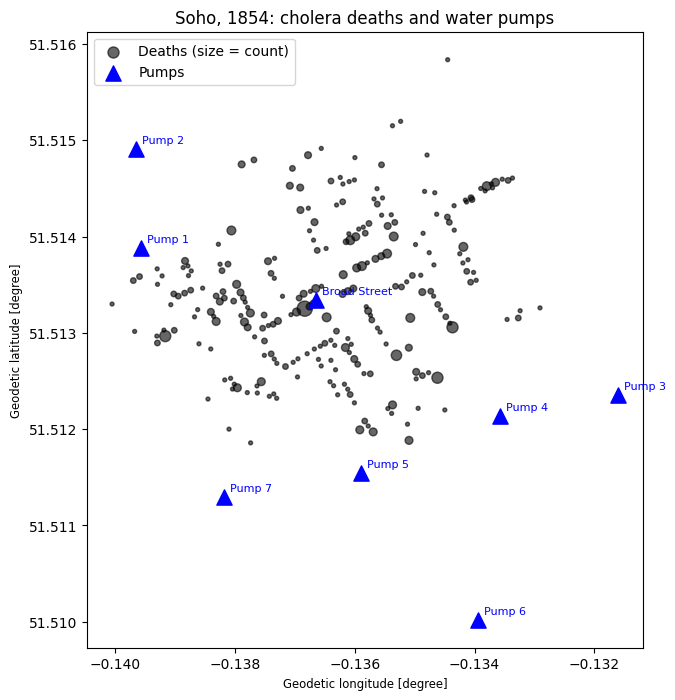

In [ ]:
deaths = pd.read_csv(URL + "snow_deaths.csv")
pumps = pd.read_csv(URL + "snow_pumps.csv")

deaths = gpd.GeoDataFrame(deaths, geometry=gpd.points_from_xy(deaths.lon, deaths.lat), crs="EPSG:4326")
pumps = gpd.GeoDataFrame(pumps, geometry=gpd.points_from_xy(pumps.lon, pumps.lat), crs="EPSG:4326")
print(deaths["deaths"].sum(), "deaths at", len(deaths), "addresses;", len(pumps), "pumps")

fig, ax = plt.subplots(figsize=(8, 8))
deaths.plot(ax=ax, markersize=deaths["deaths"] * 8, color="black", alpha=0.6, label="Deaths (size = count)")
pumps.plot(ax=ax, color="blue", marker="^", markersize=120, label="Pumps")
for _, p in pumps.iterrows():
    ax.annotate(p["name"], (p.lon, p.lat), xytext=(4, 4), textcoords="offset points", fontsize=8, color="blue")
ax.legend()
ax.set_title("Soho, 1854: cholera deaths and water pumps")
plt.show()

### Spot the problem

A colleague ran the nearest-pump analysis below and wrote:

> "Assigning each address to its nearest pump, 276 of 489 deaths (56%) were closest to Broad Street. The pump explains only about half the outbreak."

Run it, then find what's wrong. (Read any warnings carefully.)

In [ ]:
# Colleague's analysis
nearest = gpd.sjoin_nearest(deaths, pumps[["name", "geometry"]], how="left")
by_pump = nearest.groupby("name")["deaths"].sum().sort_values(ascending=False)
print(by_pump)
print(f"Share nearest Broad Street: {by_pump['Broad Street'] / by_pump.sum():.0%}")

name
Broad Street    276
Pump 4           78
Pump 1           71
Pump 5           46
Pump 7           15
Pump 2            3
Name: deaths, dtype: int64
Share nearest Broad Street: 56%


/usr/local/lib/python3.13/dist-packages/geopandas/array.py:438: UserWarning: Geometry is in a geographic CRS. Results from 'sjoin_nearest' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  warnings.warn(


### Extension exercise B
1. Explain in two sentences what's wrong with the analysis above. (Hint: at London's latitude, how many km is one degree of longitude compared with one degree of latitude? Which pumps does that favour?)
2. Fix it: project both layers to the **British National Grid**, `EPSG:27700` (units: metres), and redo the join. Add `distance_col="dist_m"` to get the distance to the nearest pump.
3. How many deaths are now nearest Broad Street? How many *addresses* changed pump?
4. Plot the deaths coloured by their (corrected) nearest pump.

In [ ]:
# your code here

**Question:** Snow actually used *walking* distance along streets, not straight lines. Why might that matter here, and what kind of data would you need to do it? (Hint: Part 3 of this notebook.)

## Raster resolution

The lecture compared 30 m, 50 cm and 10 cm imagery. **Resolution** is the size of a cell. Coarser cells are smaller files, but detail is lost. Let's aggregate our 0.1° grid to 0.5° and 1°:

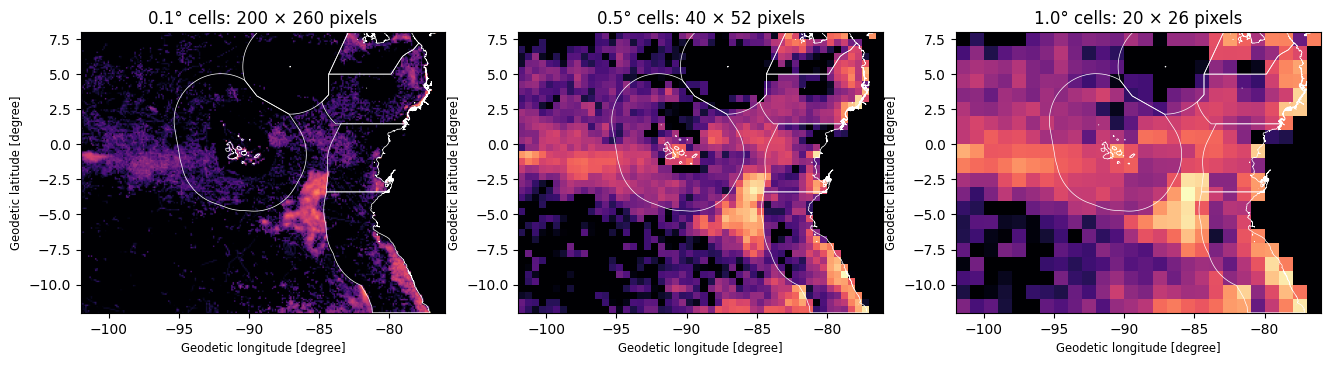

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, res in zip(axes, [0.1, 0.5, 1.0]):
    g = to_raster(effort[effort["year"] == 2024], res=res)
    ax.imshow(np.log10(g + 1), origin="lower", extent=EXTENT, cmap="magma")
    eez.boundary.plot(ax=ax, color="white", linewidth=0.5)
    ax.set_title(f"{res}° cells: {g.shape[0]} × {g.shape[1]} pixels")
plt.show()

**Question:** At 1° resolution (about 110 km), could you still see that the squid fleet stops at the Galápagos EEZ boundary? Which analysis from Part 1 or the Extension would give a different answer at 1°? (This is the MAUP again.)

## Spatial autocorrelation: why regressions on maps need care

The lecture warned that *things closer together have more in common*. Check it on our raster: correlate each cell's (log) effort with its eastern neighbour's, then with a random cell's.

In [ ]:
logr = np.log10(r24 + 1)
here, east = logr[:, :-1].ravel(), logr[:, 1:].ravel()
rng = np.random.default_rng(0)
print("Correlation with neighbour:   ", round(np.corrcoef(here, east)[0, 1], 2))
print("Correlation with random cell: ", round(np.corrcoef(here, rng.permutation(east))[0, 1], 2))

Correlation with neighbour:    0.81
Correlation with random cell:  0.0


Neighbouring cells are strongly correlated. If each cell were a row in a regression, you would have far fewer *independent* observations than rows, and your standard errors would be too small. Spatial regression methods exist to handle this.

## Which kinds of vessel are central?

A third measure from the lecture is **eigenvector** centrality: being connected to other well-connected vessels (the insider). Which vessel types are over-represented among the top 25 by each measure?

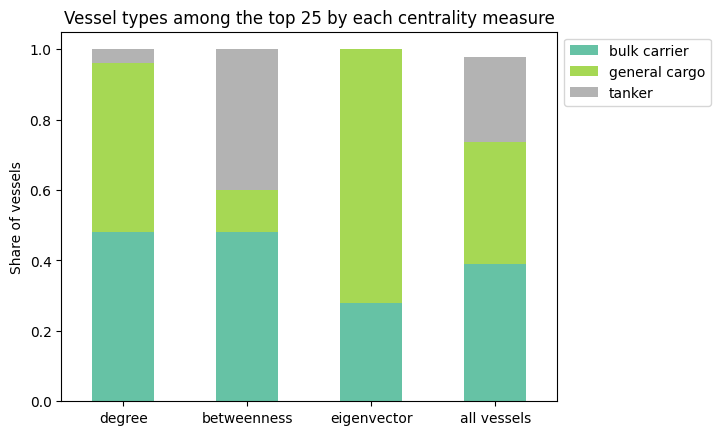

In [ ]:
cent["eigenvector"] = pd.Series(nx.eigenvector_centrality(kerch, max_iter=1000))

top25 = {m: cent.nlargest(25, m)["vessel_type"].value_counts(normalize=True) for m in ["degree", "betweenness", "eigenvector"]}
shares = pd.DataFrame(top25)
shares["all vessels"] = cent["vessel_type"].value_counts(normalize=True)
shares = shares.fillna(0).loc[["bulk carrier", "general cargo", "tanker"]]

shares.T.plot(kind="bar", stacked=True, colormap="Set2")
plt.ylabel("Share of vessels")
plt.title("Vessel types among the top 25 by each centrality measure")
plt.legend(bbox_to_anchor=(1, 1))
plt.xticks(rotation=0)
plt.show()

Tankers are over-represented among the high-**betweenness** vessels: they link groups of ships that otherwise don't interact. Different measures pick out different *roles*.

## A few hubs, many ordinary nodes

The **degree distribution** tells you whether a network is *regular* (everyone has similar numbers of links) or *heavy-tailed* (a few hubs).

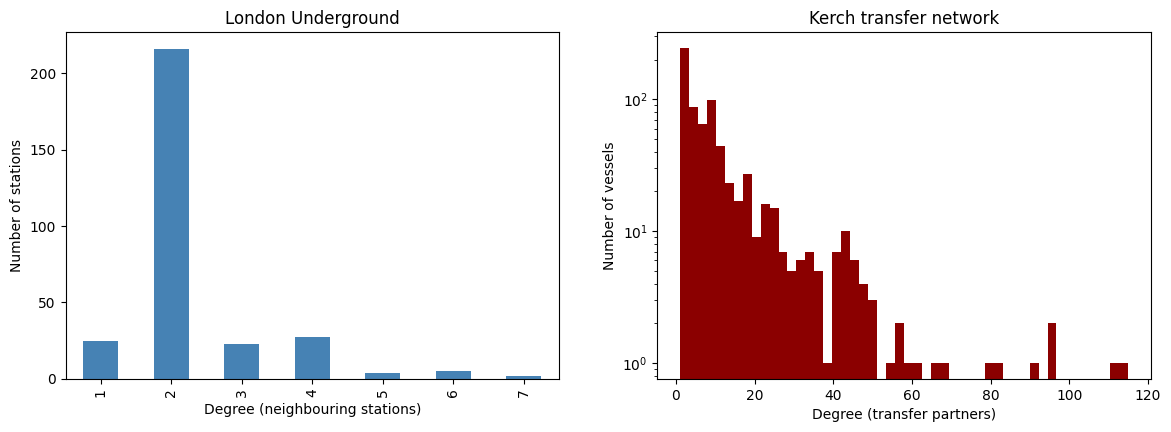

Kerch degree: median 6.0 | 99th percentile 68.0 | max 115


In [ ]:
tube_deg = pd.Series(dict(tube.degree()))
kerch_deg = pd.Series(dict(kerch.degree()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
tube_deg.value_counts().sort_index().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set(title="London Underground", xlabel="Degree (neighbouring stations)", ylabel="Number of stations")
axes[1].hist(kerch_deg, bins=50, color="darkred")
axes[1].set(title="Kerch transfer network", xlabel="Degree (transfer partners)", ylabel="Number of vessels", yscale="log")
plt.show()

print("Kerch degree: median", kerch_deg.median(), "| 99th percentile", kerch_deg.quantile(0.99).round(), "| max", kerch_deg.max())

**Question:** Why might a shipping network have hubs while the tube can't? (Think about physical constraints on a station vs. a large bulk carrier.)

## It's a small world

A **small world** has short paths between nodes *and* high **clustering** (your partners are also partners of each other). We compare with a **random network** with the same number of nodes and edges. Path lengths only make sense within a connected piece, so we use the largest **connected component**.

In [ ]:
lcc = kerch.subgraph(max(nx.connected_components(kerch), key=len)).copy()
rand = nx.gnm_random_graph(lcc.number_of_nodes(), lcc.number_of_edges(), seed=1)
rand = rand.subgraph(max(nx.connected_components(rand), key=len))

summary = pd.DataFrame({
    "Kerch": [nx.average_shortest_path_length(lcc), nx.average_clustering(lcc)],
    "Random network": [nx.average_shortest_path_length(rand), nx.average_clustering(rand)],
}, index=["Average path length", "Clustering coefficient"]).round(3)
summary

,Kerch,Random network
Average path length,3.304,2.947
Clustering coefficient,0.324,0.016


Paths are about as short as in a random network, but clustering is roughly 20 times higher: a small world.

## Communities

A **community** is a group of nodes with many edges inside and few between. **Louvain** repeatedly merges groups when that increases **modularity** (how much denser than chance the within-group edges are; above ~0.3 is notable). It only sees the edges, never vessel attributes.

In [ ]:
comms = nx.community.louvain_communities(lcc, seed=0)
print(len(comms), "communities, modularity =", round(nx.community.modularity(lcc, comms), 2))

community = {node: i for i, c in enumerate(comms) for node in c}
cent["community"] = pd.Series(community).astype("Int64")   # vessels outside the largest component get <NA>

pd.crosstab(cent["community"], cent["vessel_type"], normalize="index").round(2)

7 communities, modularity = 0.53


vessel_type,bulk carrier,general cargo,other,tanker,unknown
community,,,,,
0,0.04,0.02,0.00,0.94,0.00
1,0.14,0.07,0.00,0.79,0.00
2,0.56,0.35,0.00,0.09,0.00
3,0.39,0.52,0.01,0.04,0.03
4,0.52,0.34,0.06,0.06,0.02
5,0.54,0.41,0.00,0.04,0.01
6,0.45,0.49,0.00,0.02,0.04


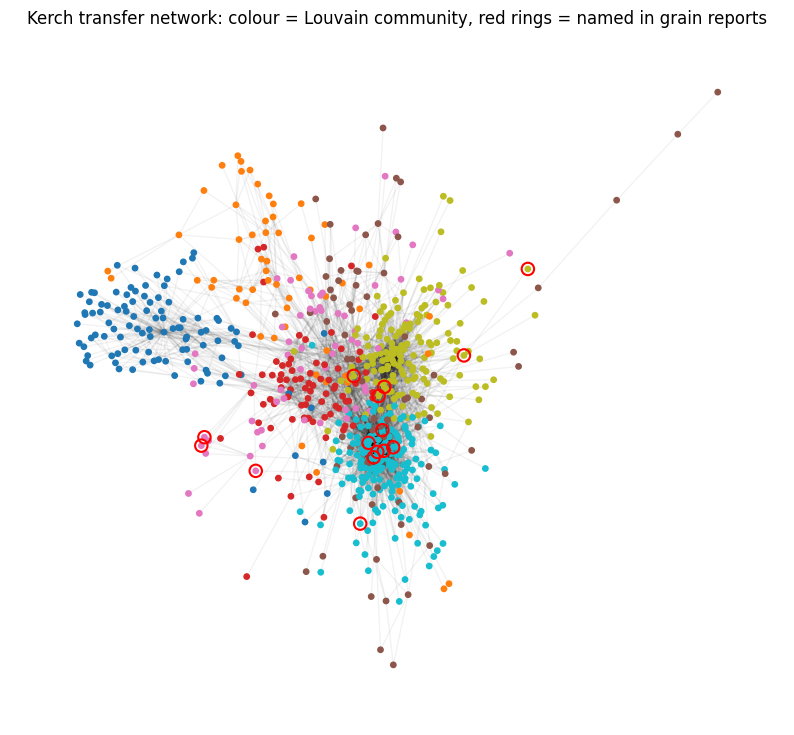

In [ ]:
layout = nx.spring_layout(lcc, seed=3, k=0.15)
fig, ax = plt.subplots(figsize=(10, 9))
nx.draw_networkx_edges(lcc, layout, ax=ax, alpha=0.05)
nx.draw_networkx_nodes(lcc, layout, ax=ax, node_size=15, cmap="tab10",
                       node_color=[community[n] for n in lcc.nodes])
named = [n for n in lcc.nodes if cent.loc[n, "named_in_grain_reports"] == 1]
nx.draw_networkx_nodes(lcc, layout, nodelist=named, ax=ax, node_size=80, node_color="none", edgecolors="red", linewidths=1.5)
ax.set_title("Kerch transfer network: colour = Louvain community, red rings = named in grain reports")
ax.set_axis_off()
plt.show()

**Question:** The algorithm never saw vessel type, yet some communities are almost entirely tankers. What does that suggest about the transfer network? (Think: would a grain ship transfer to an oil tanker?)

### Extension exercise C
Run Louvain on the **tube** network and draw it with the geographic `pos` from earlier, coloured by community. The algorithm never saw coordinates: are the communities geographic? Try `resolution=0.5` and `resolution=2` in `louvain_communities`: what changes?

In [ ]:
# your code here